# Collinearity / Redundancy Check — A Complete, Practical Guide

---

The two companion notebooks asked whether a feature has a relationship **with the target**:

* `LinearityCheck.ipynb` — is a numerical feature's relationship with the target a straight line?
* `CategoricalFeatureCheck.ipynb` — do a categorical feature's groups differ, and by how much?

This notebook asks a completely different question — one about the features' relationships **with each
other**:

> **Do two or more features carry the same information?**

If bigger buildings almost always sit on bigger floor areas, those two variables move together and
much of what they tell the model is **the same thing counted twice**.

| # | Test | Question | Data type | Section |
|---|---|---|---|---|
| 1 | **Pearson / Spearman** | Do **two numerical** features move together? | numerical ↔ numerical | §4 |
| 2 | **Cramér's V** | Do **two categorical** features split the data the same way? | categorical ↔ categorical | §5 |
| 3 | **VIF** | Can one feature be predicted from **all the others together**? | the whole numerical design matrix | §6 |

> 🎯 **The most important distinction in this notebook:**
> **Correlation looks at two variables at a time. VIF looks at one variable against ALL the others at
> once.** §7 shows a case where every pairwise correlation is a harmless 0.58 and the features are
> nonetheless *perfectly* redundant.

---
## 0. Imports

`statsmodels` provides a `variance_inflation_factor` helper, but it is **not installed in this
project's venv** — and it has a well-known trap (§6.5). We compute VIF directly from its definition
with scikit-learn instead, which is four lines and makes the formula concrete.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 150)

rng = np.random.default_rng(42)
print("ready")

ready


---
## 1. What Is Collinearity?

**Collinearity** means two or more features contain **similar or overlapping information**.

| Property | BuildingArea | FloorArea |
|---|---|---|
| A | 100 | 200 |
| B | 150 | 300 |
| C | 200 | 400 |
| D | 250 | 500 |
| E | 300 | 600 |

$$\text{FloorArea} = 2 \times \text{BuildingArea}$$

Knowing `BuildingArea` tells us **exactly** what `FloorArea` is. These two features are **redundant** —
the second one adds no information the first did not already carry.

*(Terminology: "collinearity" usually refers to a relationship between two features, and
"multicollinearity" to one involving several at once. In practice the words are used
interchangeably, and both are what this notebook screens for.)*

In [2]:
toy = pd.DataFrame({
    "Property":     list("ABCDE"),
    "BuildingArea": [100, 150, 200, 250, 300],
    "FloorArea":    [200, 300, 400, 500, 600],
})
print(toy.to_string(index=False))
print("\nFloorArea / BuildingArea =", (toy["FloorArea"] / toy["BuildingArea"]).unique(),
      " <- the same ratio every row")
print("Pearson r =", toy["BuildingArea"].corr(toy["FloorArea"]))

Property  BuildingArea  FloorArea
       A           100        200
       B           150        300
       C           200        400
       D           250        500
       E           300        600

FloorArea / BuildingArea = [2.]  <- the same ratio every row
Pearson r = 0.9999999999999998


---
## 2. Why Is Redundancy a Problem?

### 2.1 The intuition: one concept counted twice

Imagine a model that scores how different two properties are by adding up their difference on each
feature:

```
difference in building_area = 8
difference in floor_area    = 9
        → model sees: 8 + 9 = 17
```

> 🧠 Much of that `17` is really **one** underlying concept — *size* — counted **twice**. Redundant
> features quietly give a single concept **double the influence** over the model's decisions.

### 2.2 The concrete cost: unstable coefficients

That intuition has a precise, measurable consequence. When two features carry the same information,
the model **cannot tell which of them deserves the credit** — and it will happily hand a large
positive weight to one and a compensating negative weight to the other, because many different
combinations fit the data almost equally well.

The demonstration below refits the same model on 25 bootstrap resamples of the real data and watches
the coefficients move. `Rooms` and `Bedroom2` (the dataset's two different counts of bedrooms)
correlate at **0.94**.

In [3]:
df = pd.read_csv("../data/melb_data.csv")

d = df[["Price", "Rooms", "Bedroom2", "Bathroom", "Car", "BuildingArea", "Landsize",
        "YearBuilt", "Distance", "Lattitude", "Longtitude", "Propertycount",
        "Type", "Method", "Regionname", "CouncilArea", "Suburb"]].copy()

d = d[(d["Price"] > 0) & (d["BuildingArea"] >= 30) & (d["Landsize"] > 0)]
d = d[d["YearBuilt"].between(1850, 2018)]
d = d.dropna(subset=["Price", "BuildingArea", "Landsize", "YearBuilt", "Rooms", "Bedroom2",
                     "Bathroom", "Car", "Distance"]).reset_index(drop=True)

d["LogPrice"]     = np.log(d["Price"])
d["log_building"] = np.log(d["BuildingArea"])
d["log_land"]     = np.log(d["Landsize"])
d["log_coverage"] = np.log(d["BuildingArea"] / d["Landsize"])
d["Age"]          = 2018 - d["YearBuilt"]

print(f"rows: {len(d):,}")
print(f"corr(Rooms, Bedroom2) = {d['Rooms'].corr(d['Bedroom2']):.3f}\n")

FEATS = ["Rooms", "Bedroom2", "Bathroom", "log_building", "Distance"]

def bootstrap_coefs(features, n_boot=25):
    rows = []
    for seed in range(n_boot):
        b = d.sample(len(d), replace=True, random_state=seed)
        rows.append(LinearRegression().fit(b[features], b["LogPrice"]).coef_)
    return pd.DataFrame(rows, columns=features)

both = bootstrap_coefs(FEATS)
print("Coefficients across 25 bootstrap resamples, WITH both Rooms and Bedroom2:")
print(both.agg(["mean", "std", "min", "max"]).round(3).to_string())

one = bootstrap_coefs([f for f in FEATS if f != "Bedroom2"])
print("\nSame thing, WITHOUT Bedroom2:")
print(one.agg(["mean", "std", "min", "max"]).round(3).to_string())

rows: 5,748
corr(Rooms, Bedroom2) = 0.945

Coefficients across 25 bootstrap resamples, WITH both Rooms and Bedroom2:
      Rooms  Bedroom2  Bathroom  log_building  Distance
mean  0.101     0.002     0.048         0.562    -0.036
std   0.020     0.020     0.008         0.025     0.001
min   0.058    -0.033     0.030         0.519    -0.037
max   0.137     0.050     0.069         0.622    -0.034

Same thing, WITHOUT Bedroom2:
      Rooms  Bathroom  log_building  Distance
mean  0.103     0.047         0.562    -0.036
std   0.011     0.008         0.025     0.001
min   0.079     0.028         0.519    -0.037
max   0.117     0.069         0.622    -0.034


**What just happened, in two numbers:**

* **`Bedroom2`'s coefficient changes sign** across resamples — it runs from **−0.033 to +0.050**
  around a mean of **0.002**. Is an extra bedroom worth more money or less? The model cannot say; its
  answer depends on which rows it happened to see.
* **`Rooms` becomes roughly twice as stable once `Bedroom2` is removed** — its standard deviation
  falls from **0.020 to 0.011**, and its range tightens from **0.058–0.137** to **0.079–0.117**.

Nothing about the *houses* changed between those two tables. Only whether the model was asked to split
one piece of information between two columns.

> 📌 **This is what collinearity actually damages: the coefficients, not necessarily the predictions.**
> §9.4 returns to this with the other half of the evidence — and the answer surprises most people.

---
## 3. The Three Tests

Three tests, because redundancy comes in three different shapes:

| Test | Question | Data type |
|---|---|---|
| **Pairwise correlation** | Do two **numerical** features move together? | numerical |
| **Cramér's V** | Do two **categorical** features divide observations into similar groups? | categorical |
| **VIF** | Can one feature be predicted from **several other features together**? | numerical design matrix |

The first two are **pairwise**. The third is **multivariate**, and that difference is the entire
reason VIF exists.

---
## 4. Test 1 — Correlation

For two numerical variables, correlation asks: **when X changes, does Y tend to change with it?**

### 4.1 Pearson Correlation

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \times \sum (y_i - \bar{y})^2}}$$

Range: **−1 ≤ r ≤ 1**

| Pearson r | Relationship |
|---|---|
| +1 | perfect positive |
| +0.9 | very strong positive |
| +0.7 | strong positive |
| 0 | no linear relationship |
| −0.7 | strong negative |
| −1 | perfect negative |

### 4.2 Worked Calculation

Using the `BuildingArea` / `FloorArea` table: mean(X) = 200, mean(Y) = 400.

| X | Y | X−X̄ | Y−Ȳ | Product |
|---|---|---|---|---|
| 100 | 200 | −100 | −200 | 20,000 |
| 150 | 300 | −50 | −100 | 5,000 |
| 200 | 400 | 0 | 0 | 0 |
| 250 | 500 | 50 | 100 | 5,000 |
| 300 | 600 | 100 | 200 | 20,000 |

Every point moves in exactly the same direction, so **r = 1**.

> 💡 An `r` of 1 means these two variables contain **essentially the same information**.

In [4]:
x, y = toy["BuildingArea"], toy["FloorArea"]
work = pd.DataFrame({"X": x, "Y": y, "X-Xbar": x - x.mean(), "Y-Ybar": y - y.mean()})
work["product"]  = work["X-Xbar"] * work["Y-Ybar"]
work["X-Xbar^2"] = work["X-Xbar"] ** 2
work["Y-Ybar^2"] = work["Y-Ybar"] ** 2
print(work.to_string(index=False))

num   = work["product"].sum()
den   = np.sqrt(work["X-Xbar^2"].sum() * work["Y-Ybar^2"].sum())
print(f"\nnumerator   = {num:,.0f}")
print(f"denominator = sqrt({work['X-Xbar^2'].sum():,.0f} x {work['Y-Ybar^2'].sum():,.0f}) = {den:,.0f}")
print(f"r = {num}/{den} = {num/den:.4f}")
print(f"\npandas .corr() : {x.corr(y):.4f}   (matches)")

  X   Y  X-Xbar  Y-Ybar  product  X-Xbar^2  Y-Ybar^2
100 200  -100.0  -200.0  20000.0   10000.0   40000.0
150 300   -50.0  -100.0   5000.0    2500.0   10000.0
200 400     0.0     0.0      0.0       0.0       0.0
250 500    50.0   100.0   5000.0    2500.0   10000.0
300 600   100.0   200.0  20000.0   10000.0   40000.0

numerator   = 50,000
denominator = sqrt(25,000 x 100,000) = 50,000
r = 50000.0/50000.0 = 1.0000

pandas .corr() : 1.0000   (matches)


### 4.3 Pearson vs Spearman for Redundancy

Pearson detects **linear** association; Spearman detects **monotonic** association (the companion
`LinearityCheck.ipynb` explains the difference in full).

For redundancy screening you generally want **both**, and reading them together tells you something:

> `Pearson = 0.70` with `Spearman = 0.95` means the variables **strongly move together**, but their
> relationship is not a straight line. That is still redundancy — a curved relationship carries
> information just as surely as a straight one — and a Pearson-only screen would under-report it.

### 4.4 Correlation Threshold

There is **no universal cutoff**, but the common screening rule is **|r| > 0.8** (or the stricter
0.9) as a warning sign worth investigating.

| Feature 1 | Feature 2 | Pearson |
|---|---|---|
| BuildingArea | FloorArea | **0.97** |
| BuildingArea | LandArea | 0.62 |
| LandArea | FloorArea | 0.65 |
| NumFloors | Height | **0.91** |

*Investigate:* `BuildingArea ↔ FloorArea` and `NumFloors ↔ Height`.

The cell below runs this screen across the real numerical features.

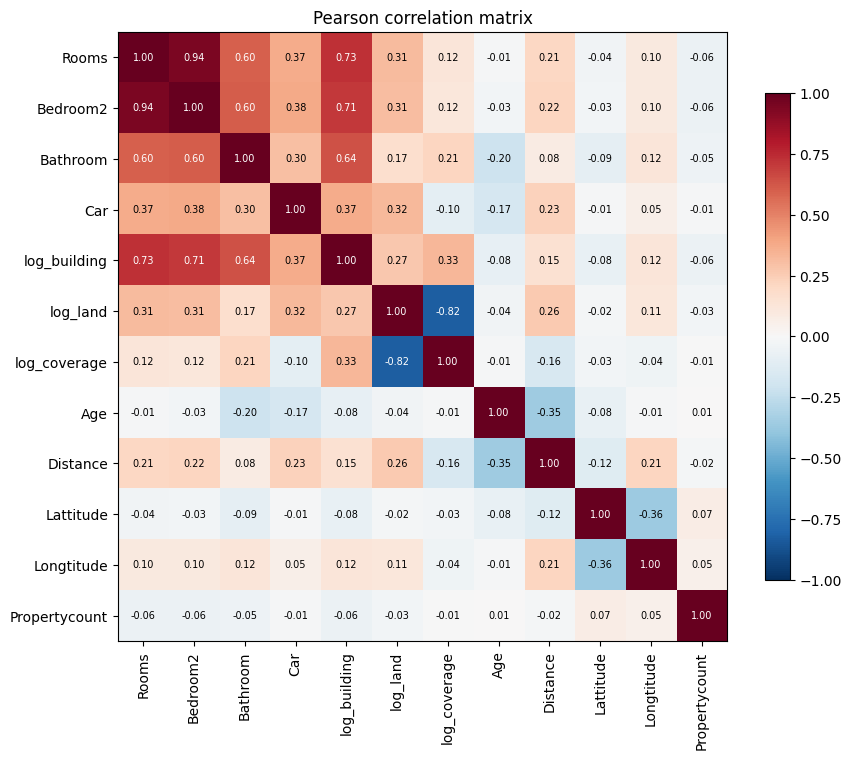

Pairs exceeding |r| > 0.8:
feature 1    feature 2  pearson  spearman
    Rooms     Bedroom2    0.945     0.951
 log_land log_coverage   -0.823    -0.777


In [5]:
NUM = ["Rooms", "Bedroom2", "Bathroom", "Car", "log_building", "log_land", "log_coverage",
       "Age", "Distance", "Lattitude", "Longtitude", "Propertycount"]

corr_p = d[NUM].corr(method="pearson")
corr_s = d[NUM].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr_p, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM))); ax.set_xticklabels(NUM, rotation=90)
ax.set_yticks(range(len(NUM))); ax.set_yticklabels(NUM)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        v = corr_p.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.55 else "black")
ax.set_title("Pearson correlation matrix")
ax.grid(False); fig.colorbar(im, shrink=0.8); plt.tight_layout(); plt.show()


def flag_correlated_pairs(data, cols, threshold=0.8):
    # Upper triangle only - a correlation matrix repeats every pair twice.
    rows = []
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            p = data[a].corr(data[b])
            s = data[a].corr(data[b], method="spearman")
            if max(abs(p), abs(s)) > threshold:
                rows.append({"feature 1": a, "feature 2": b,
                             "pearson": round(p, 3), "spearman": round(s, 3)})
    return pd.DataFrame(rows).sort_values("pearson", key=abs, ascending=False)

print(f"Pairs exceeding |r| > 0.8:")
print(flag_correlated_pairs(d, NUM).to_string(index=False))

Two pairs trip the screen:

* **`Rooms` ↔ `Bedroom2` (0.94)** — two different counts of essentially the same thing. This is the
  pair that destabilised the coefficients in §2.2.
* **`log_land` ↔ `log_coverage` (−0.82)** — related *by construction*, as §6 will make explicit.

> ⚠️ **The limitation of this entire section:** correlation only ever looks at **one pair at a time**.
> It cannot see redundancy that involves several variables working together — and §6 and §7 show that
> such redundancy can be **perfect** while every pairwise number looks innocent.

---
## 5. Test 2 — Cramér's V

Correlation is built for numbers. Categories like `Concrete`, `Steel`, `Brick` have no numerical
meaning — you cannot compute a Pearson correlation on them (and as
`CategoricalFeatureCheck.ipynb` §1 showed, encoding them as numbers just measures your arbitrary
encoding).

**Cramér's V** asks: **do these two categorical variables carry the same grouping?**

### 5.1 Worked Example

| Property | Construction | Class |
|---|---|---|
| A | Concrete | Premium |
| B | Concrete | Premium |
| C | Concrete | Premium |
| D | Steel | Standard |
| E | Steel | Standard |
| F | Steel | Standard |

Knowing `Construction` tells us `Class` **exactly** — a perfect association, so **V = 1**.

### 5.2 How Cramér's V Is Calculated

First build the contingency table, then the chi-square statistic:

$$\chi^2 = \sum \frac{(O - E)^2}{E}
\qquad\text{where}\qquad
E = \frac{\text{row total} \times \text{column total}}{\text{grand total}}$$

Then:

$$V = \sqrt{\frac{\chi^2}{n \times \min(r-1,\ c-1)}}$$

where `n` = total observations, `r` = number of rows, `c` = number of columns.

**Hand calculation.** Every expected cell = (3×3)/6 = **1.5**, so:

$$\chi^2 = \frac{(3-1.5)^2}{1.5} + \frac{(0-1.5)^2}{1.5} + \frac{(0-1.5)^2}{1.5} + \frac{(3-1.5)^2}{1.5} = 6$$

With n = 6 and min(r−1, c−1) = 1:

$$V = \sqrt{\frac{6}{6 \times 1}} = 1$$

In [6]:
cat_toy = pd.DataFrame({
    "Property":     list("ABCDEF"),
    "Construction": ["Concrete"]*3 + ["Steel"]*3,
    "Class":        ["Premium"]*3  + ["Standard"]*3,
})
table = pd.crosstab(cat_toy["Construction"], cat_toy["Class"])
print("Contingency table (observed):"); print(table.to_string())

chi2, p, dof, expected = chi2_contingency(table, correction=False)
print("\nExpected under independence:")
print(pd.DataFrame(expected, index=table.index, columns=table.columns).to_string())
print(f"\nchi^2 = {chi2}  (hand calculation: 6)")

n    = table.to_numpy().sum()
r, c = table.shape
print(f"V = sqrt({chi2} / ({n} x min({r-1}, {c-1}))) = {np.sqrt(chi2 / (n * min(r-1, c-1))):.3f}")


def cramers_v(x, y, bias_corrected=False):
    # Cramer's V for two categorical Series. See 5.5 for why the correction matters.
    table = pd.crosstab(x, y)
    chi2  = chi2_contingency(table, correction=False)[0]
    n     = table.to_numpy().sum()
    r, c  = table.shape
    if not bias_corrected:
        return np.sqrt(chi2 / (n * min(r - 1, c - 1)))
    phi2 = max(0.0, chi2 / n - (r - 1) * (c - 1) / (n - 1))
    r_c  = r - (r - 1) ** 2 / (n - 1)
    c_c  = c - (c - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(r_c - 1, c_c - 1))

print(f"\ncramers_v() on the toy data = {cramers_v(cat_toy['Construction'], cat_toy['Class']):.3f}")

Contingency table (observed):
Class         Premium  Standard
Construction                   
Concrete            3         0
Steel               0         3

Expected under independence:
Class         Premium  Standard
Construction                   
Concrete          1.5       1.5
Steel             1.5       1.5

chi^2 = 6.0  (hand calculation: 6)
V = sqrt(6.0 / (6 x min(1, 1))) = 1.000

cramers_v() on the toy data = 1.000


### 5.3 Interpreting Cramér's V

Range: **0 ≤ V ≤ 1**. Unlike Pearson there is **no direction** — categories have no "positive" or
"negative", only "associated" or "not".

| V | Approximate interpretation |
|---|---|
| 0 | no association |
| 0.1 – 0.2 | weak |
| 0.2 – 0.4 | moderate |
| 0.4 – 0.6 | strong |
| > 0.6 | very strong |

> 💡 Rough guidelines, not universal rules — the right reading depends on table size and domain. For
> **redundancy screening**, flag **V > 0.8** for investigation.

### 5.4 Which Test for Which Pair?

| Feature pair type | Test to use |
|---|---|
| numerical ↔ numerical | Pearson / Spearman (§4) |
| categorical ↔ categorical | **Cramér's V** (§5) |
| numerical ↔ categorical | ANOVA / η² — see `CategoricalFeatureCheck.ipynb` |

In [7]:
CATS = ["Type", "Method", "Regionname", "CouncilArea", "Suburb"]
dc = d.dropna(subset=CATS)

rows = []
for i, a in enumerate(CATS):
    for b in CATS[i + 1:]:
        t = pd.crosstab(dc[a], dc[b])
        rows.append({"feature 1": a, "feature 2": b, "table": f"{t.shape[0]}x{t.shape[1]}",
                     "V": round(cramers_v(dc[a], dc[b]), 3),
                     "V (corrected)": round(cramers_v(dc[a], dc[b], True), 3)})
cv_table = pd.DataFrame(rows).sort_values("V", ascending=False)
cv_table["flag"] = np.where(cv_table["V (corrected)"] > 0.8, "REDUNDANT - investigate", "-")
print(cv_table.to_string(index=False))

  feature 1   feature 2  table     V  V (corrected)                    flag
 Regionname      Suburb  8x287 1.000          0.972 REDUNDANT - investigate
CouncilArea      Suburb 31x287 0.986          0.960 REDUNDANT - investigate
 Regionname CouncilArea   8x31 0.805          0.802 REDUNDANT - investigate
       Type      Suburb  3x287 0.310          0.200                       -
     Method      Suburb  5x287 0.274          0.138                       -
     Method CouncilArea   5x31 0.150          0.129                       -
       Type CouncilArea   3x31 0.148          0.126                       -
     Method  Regionname    5x8 0.102          0.095                       -
       Type  Regionname    3x8 0.084          0.076                       -
       Type      Method    3x5 0.038          0.025                       -


**`Regionname` ↔ `Suburb` = 1.000.** That is not an approximation — every suburb sits inside exactly
one region, so knowing the suburb tells you the region with **certainty**. The two columns are a
**hierarchy**, and including both gives the model the same geography twice.

`CouncilArea ↔ Suburb` (**0.986**) and `Regionname ↔ CouncilArea` (**0.805**) are the same story one
level down — a geography hierarchy, entered three times. Meanwhile `Type ↔ Method` (**0.038**)
confirms the measure behaves: what a property *is* and how it *sold* really are close to unrelated.

### 5.5 The Trap: Cramér's V Inflates With Table Size

Exactly like η² in `CategoricalFeatureCheck.ipynb` §8.2, **more categories mechanically means higher
V**, even when the grouping is meaningless. The cell below pairs three real columns against a column
of **pure random numbers** — and the raw V for the 287-level `Suburb` comes back at **0.238**, well
above the 0.2 "moderate association" band, purely from having a big table. The corrected version
returns **0.026**.

In [8]:
dc = dc.copy()
dc["rand_50"] = rng.integers(0, 50, len(dc)).astype(str)

for a in ["Suburb", "CouncilArea", "Type"]:
    v  = cramers_v(dc[a], dc["rand_50"])
    vc = cramers_v(dc[a], dc["rand_50"], bias_corrected=True)
    print(f"{a:12s} ({dc[a].nunique():3d} levels) x rand_50 :  V = {v:.3f}   V(corrected) = {vc:.3f}")

v_raw  = cramers_v(dc["Suburb"], dc["rand_50"])
v_corr = cramers_v(dc["Suburb"], dc["rand_50"], bias_corrected=True)
print(f"\n-> 'Suburb vs pure noise' scores V = {v_raw:.3f} on the raw measure - a number you might")
print(f"   read as a weak but real association. The bias-corrected version returns {v_corr:.3f}: nothing.")
print("   Always compare V across tables of SIMILAR size, or use the corrected form.")

Suburb       (287 levels) x rand_50 :  V = 0.238   V(corrected) = 0.026
CouncilArea  ( 31 levels) x rand_50 :  V = 0.097   V(corrected) = 0.000
Type         (  3 levels) x rand_50 :  V = 0.101   V(corrected) = 0.026

-> 'Suburb vs pure noise' scores V = 0.238 on the raw measure - a number you might
   read as a weak but real association. The bias-corrected version returns 0.026: nothing.
   Always compare V across tables of SIMILAR size, or use the corrected form.


---
## 6. Test 3 — VIF (Variance Inflation Factor)

Don't let the name put you off. The idea is simple:

> **Can one feature be predicted from the OTHER features together?**

This is exactly what pairwise correlation **cannot** detect.

### 6.1 Why Pairwise Correlation Misses Redundancy

Our dataset has a textbook example built into it:

$$\text{coverage} = \frac{\text{BuildingArea}}{\text{LandArea}}
\qquad\Longrightarrow\qquad
\log(\text{coverage}) = \log(\text{BuildingArea}) - \log(\text{LandArea})$$

The three log features are **exactly linearly dependent** — any one is perfectly determined by the
other two. Yet look at their pairwise correlations in the §4 matrix: `log_building ↔ log_land` is
**0.27** and `log_building ↔ log_coverage` is **0.33**. Utterly innocent numbers.

**A pairwise screen would wave two of those three pairs straight through**, while the three columns
together contain a perfect redundancy.

### 6.2 The Basic Idea

To calculate VIF for `BuildingArea`, temporarily make it the **target** and predict it from all the
other features:

$$\text{BuildingArea} = \beta_0 + \beta_1 \cdot \text{LandArea} + \beta_2 \cdot \text{Coverage} + \varepsilon$$

Take the **R²** of that regression, and:

$$VIF_j = \frac{1}{1 - R^2_j}$$

| Other features explain X by… | VIF | Concern level |
|---|---|---|
| R² = 0.50 | 2 | not particularly concerning |
| R² = 0.90 | **10** | strong warning of multicollinearity |
| R² = 0.99 | **100** | almost completely explained by the others |

Notice the shape of that: VIF grows **explosively** as R² approaches 1, so small increases near the
top matter enormously.

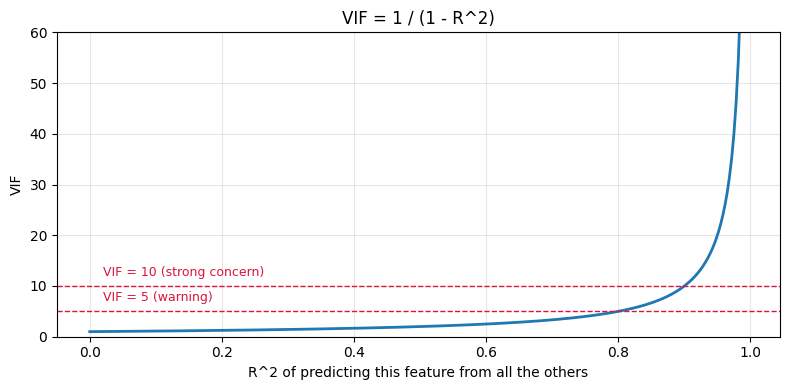

  R^2 = 0.0    -> VIF =        1.0
  R^2 = 0.5    -> VIF =        2.0
  R^2 = 0.8    -> VIF =        5.0
  R^2 = 0.9    -> VIF =       10.0
  R^2 = 0.95   -> VIF =       20.0
  R^2 = 0.99   -> VIF =      100.0
  R^2 = 0.999  -> VIF =    1,000.0


In [9]:
r2_grid = np.linspace(0, 0.995, 300)
plt.figure(figsize=(8, 4))
plt.plot(r2_grid, 1 / (1 - r2_grid), lw=2)
for thr, lbl in [(5, "VIF = 5 (warning)"), (10, "VIF = 10 (strong concern)")]:
    plt.axhline(thr, ls="--", lw=1, color="crimson")
    plt.text(0.02, thr + 2, lbl, color="crimson", fontsize=9)
plt.ylim(0, 60); plt.xlabel("R^2 of predicting this feature from all the others")
plt.ylabel("VIF"); plt.title("VIF = 1 / (1 - R^2)")
plt.tight_layout(); plt.show()

for r2 in [0.0, 0.5, 0.8, 0.9, 0.95, 0.99, 0.999]:
    print(f"  R^2 = {r2:<6} -> VIF = {1/(1-r2):>10,.1f}")

### 6.3 What VIF Actually Measures

> 🧠 **High VIF = this feature does not contain much unique information** relative to the other
> features. Low VIF = it brings something of its own.

The name comes from what it does to the *variance of the estimated coefficient*: a VIF of 10 means
that coefficient's variance is **10× larger** than it would be if the feature were uncorrelated with
the rest. That is §2.2's unstable coefficients, quantified.

### 6.4 VIF Interpretation

| VIF | Interpretation |
|---|---|
| 1 | no multicollinearity |
| 1 – 2 | very low |
| 2 – 5 | usually acceptable |
| **5 – 10** | potential concern |
| **> 10** | strong concern |

> 💡 Some workflows warn at VIF > 5, others at > 10. **There is no magical universal cutoff** — treat
> VIF as a **diagnostic**, not an automatic "delete this feature" rule (§9).

### 6.5 Worked VIF Example

> ⚠️ **A trap in the usual `statsmodels` recipe.** `variance_inflation_factor(X.values, i)` assumes
> your matrix **already contains an intercept column**. Pass a raw feature matrix without one and the
> VIFs come back wrong — usually inflated, sometimes wildly. Add a constant first
> (`sm.add_constant`), or compute VIF from the definition as below, where `LinearRegression` fits the
> intercept for you.

In [10]:
def vif_table(data, features):
    rows = []
    for col in features:
        others = [f for f in features if f != col]
        r2 = LinearRegression().fit(data[others], data[col]).score(data[others], data[col])
        vif = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
        rows.append({"feature": col, "R^2 from others": round(r2, 4), "VIF": vif})
    out = pd.DataFrame(rows).sort_values("VIF", ascending=False)
    out["VIF"] = out["VIF"].map(lambda v: "inf" if np.isinf(v) else f"{v:,.2f}")
    return out

TRIO = ["log_building", "log_land", "log_coverage"]
print("Is the relationship exact?")
print("  max |log_coverage - (log_building - log_land)| =",
      (d["log_coverage"] - (d["log_building"] - d["log_land"])).abs().max())

print("\nPairwise correlations within the trio (all look harmless except one):")
print(d[TRIO].corr().round(3).to_string())

print("\nVIF for the same three columns:")
print(vif_table(d, TRIO).to_string(index=False))

Is the relationship exact?
  max |log_coverage - (log_building - log_land)| = 1.3322676295501878e-15

Pairwise correlations within the trio (all look harmless except one):
              log_building  log_land  log_coverage
log_building         1.000     0.267         0.329
log_land             0.267     1.000        -0.823
log_coverage         0.329    -0.823         1.000

VIF for the same three columns:
     feature  R^2 from others VIF
log_building              1.0 inf
    log_land              1.0 inf
log_coverage              1.0 inf


**There it is.** Two of the three pairwise correlations are **0.27** and **0.33** — nothing a screening
threshold would ever flag — and yet **every VIF in the trio is infinite**, because the three columns
are an exact linear dependency. R² of predicting any one from the other two is **1.0**.

This is the single most important cell in the notebook: *pairwise correlation screened this as fine,
and it was perfectly redundant.*

In [11]:
print("VIF across all numerical features:")
print(vif_table(d, NUM).to_string(index=False))

print("\n--- after dropping log_coverage (the derived feature) ---")
print(vif_table(d, [f for f in NUM if f != "log_coverage"]).to_string(index=False))

VIF across all numerical features:
      feature  R^2 from others   VIF
     log_land           1.0000   inf
 log_coverage           1.0000   inf
 log_building           1.0000   inf
        Rooms           0.9017 10.17
     Bedroom2           0.8962  9.63
     Bathroom           0.5017  2.01
     Distance           0.2734  1.38
          Car           0.2322  1.30
          Age           0.2308  1.30
   Longtitude           0.1794  1.22
    Lattitude           0.1649  1.20
Propertycount           0.0176  1.02

--- after dropping log_coverage (the derived feature) ---
      feature  R^2 from others   VIF
        Rooms           0.9017 10.17
     Bedroom2           0.8962  9.63
 log_building           0.6066  2.54
     Bathroom           0.5017  2.01
     Distance           0.2734  1.38
          Car           0.2322  1.30
          Age           0.2308  1.30
     log_land           0.1835  1.22
   Longtitude           0.1794  1.22
    Lattitude           0.1649  1.20
Propertycount     

Dropping the one **derived** column collapses three infinities at a stroke. What remains is the
`Rooms` / `Bedroom2` pair at **VIF ≈ 10 / 9.6** — genuine redundancy, but of the ordinary kind, and it
is now the only thing left to decide about.

### 6.6 A Simple Analogy

Imagine identifying someone's **height** from shoe size, leg length, and inseam. Individually, each
might only *moderately* predict height. But **together** they can predict it very accurately.

VIF asks exactly that question: *how much can the other measurements collectively reconstruct this
one?*

---
## 7. Why VIF Is Different From Correlation

Suppose all three individual correlations look merely moderate:

```
X ↔ A = 0.6        X ↔ B = 0.6        X ↔ C = 0.6
```

You might conclude that nothing is strongly correlated with X. But if **X = A + B − C**, then A, B and
C **together** explain X perfectly — and VIF catches it while correlation, looking at one pair at a
time, never can.

```
Correlation asks:   X ↔ A,   X ↔ B,   X ↔ C     (one at a time)
VIF asks:           A + B + C  →  X             (all together)
```

The cell below builds exactly that situation from scratch.

In [12]:
n = 2000
A = rng.normal(size=n)
B = rng.normal(size=n)
C = rng.normal(size=n)
X = A + B - C              # exact linear combination

sim = pd.DataFrame({"A": A, "B": B, "C": C, "X": X})

print("Every pairwise correlation with X:")
for col in ["A", "B", "C"]:
    print(f"  corr(X, {col}) = {sim['X'].corr(sim[col]):+.3f}")
print("\n-> all around 0.58 (theoretically 1/sqrt(3)), nowhere near any screening threshold.")
print("   A pairwise screen at |r| > 0.8 reports: all clear.")

print("\nFull correlation matrix (A, B, C are independent of each other):")
print(sim.corr().round(3).to_string())

print("\nVIF on the same four columns:")
print(vif_table(sim, ["A", "B", "C", "X"]).to_string(index=False))
print("\n-> infinite. The redundancy was never in any PAIR - it was in the COMBINATION.")

Every pairwise correlation with X:
  corr(X, A) = +0.593
  corr(X, B) = +0.609
  corr(X, C) = -0.546

-> all around 0.58 (theoretically 1/sqrt(3)), nowhere near any screening threshold.
   A pairwise screen at |r| > 0.8 reports: all clear.

Full correlation matrix (A, B, C are independent of each other):
       A      B      C      X
A  1.000  0.057  0.012  0.593
B  0.057  1.000  0.015  0.609
C  0.012  0.015  1.000 -0.546
X  0.593  0.609 -0.546  1.000

VIF on the same four columns:
feature  R^2 from others VIF
      A              1.0 inf
      B              1.0 inf
      C              1.0 inf
      X              1.0 inf

-> infinite. The redundancy was never in any PAIR - it was in the COMBINATION.


---
## 8. A Practical Workflow

| Step | What to do | Flag when |
|---|---|---|
| **A** | Numerical pairwise: `X.corr(method="spearman")` | **\|r\| > 0.8** |
| **B** | Categorical pairwise: Cramér's V for every pair | **V > 0.8** (use the corrected form) |
| **C** | VIF on the numerical design matrix | **VIF > 5** warning, **> 10** stronger warning |

Order matters: A and B are cheap and catch the obvious duplicates; C then catches the subtle
multi-feature redundancy the first two structurally cannot see.

The function below runs all three in one call.

In [13]:
def collinearity_report(data, numeric, categorical=(), r_threshold=0.8, v_threshold=0.8):
    print("=" * 78)
    print("STEP A - numerical pairs  (|r| > %.2f)" % r_threshold)
    print("=" * 78)
    pairs = flag_correlated_pairs(data, numeric, r_threshold)
    print(pairs.to_string(index=False) if len(pairs) else "  none flagged")

    if len(categorical):
        print("\n" + "=" * 78)
        print("STEP B - categorical pairs  (corrected V > %.2f)" % v_threshold)
        print("=" * 78)
        sub, rows = data.dropna(subset=list(categorical)), []
        for i, a in enumerate(categorical):
            for b in list(categorical)[i + 1:]:
                vc = cramers_v(sub[a], sub[b], bias_corrected=True)
                if vc > v_threshold:
                    rows.append({"feature 1": a, "feature 2": b, "V (corrected)": round(vc, 3)})
        print(pd.DataFrame(rows).to_string(index=False) if rows else "  none flagged")

    print("\n" + "=" * 78)
    print("STEP C - VIF  (all features together)")
    print("=" * 78)
    vt = vif_table(data, numeric)
    vt["concern"] = [("EXACT DEPENDENCY" if v == "inf"
                      else "strong" if float(v.replace(",", "")) > 10
                      else "potential" if float(v.replace(",", "")) > 5
                      else "-") for v in vt["VIF"]]
    print(vt.to_string(index=False))
    return pairs, vt

_ = collinearity_report(d, NUM, CATS)

STEP A - numerical pairs  (|r| > 0.80)
feature 1    feature 2  pearson  spearman
    Rooms     Bedroom2    0.945     0.951
 log_land log_coverage   -0.823    -0.777

STEP B - categorical pairs  (corrected V > 0.80)
  feature 1   feature 2  V (corrected)
 Regionname CouncilArea          0.802
 Regionname      Suburb          0.972
CouncilArea      Suburb          0.960

STEP C - VIF  (all features together)
      feature  R^2 from others   VIF          concern
     log_land           1.0000   inf EXACT DEPENDENCY
 log_coverage           1.0000   inf EXACT DEPENDENCY
 log_building           1.0000   inf EXACT DEPENDENCY
        Rooms           0.9017 10.17           strong
     Bedroom2           0.8962  9.63        potential
     Bathroom           0.5017  2.01                -
     Distance           0.2734  1.38                -
          Car           0.2322  1.30                -
          Age           0.2308  1.30                -
   Longtitude           0.1794  1.22              

---
## 9. Important Cautions

### 9.1 Don't Automatically Delete Everything With High Correlation

This is a **screening** process, not an automatic deletion rule. If `BuildingArea ↔ FloorArea` has
r = 0.95, don't blindly delete one — ask **which one is more meaningful**. `BuildingArea` may
represent physical size directly, while `FloorArea` captures total usable space. Decide which
provides the more useful **unique** signal.

For our two flagged pairs:

| Pair | Decision |
|---|---|
| `log_coverage` vs `log_building`/`log_land` | **drop `log_coverage`** — it is *derived* from the other two, so it is the one adding nothing. (Or keep coverage and drop one input, if coverage is the more interpretable quantity for your problem.) |
| `Rooms` vs `Bedroom2` | keep **`Rooms`** — `Bedroom2` is scraped from a second source and is the less reliable of the two. This is a **data-provenance** judgement, not a statistical one. |

### 9.2 Redundancy vs Causation

These tests tell you about statistical **association / redundancy** — **not** that "BuildingArea
*causes* FloorArea". You are asking whether features carry overlapping information, not establishing
cause.

### 9.3 High VIF Doesn't Automatically Mean "Delete"

VIF is a **redundancy diagnostic**. The final question is always: *does this feature add unique
information, or is it counting an existing concept again?*

```
Correlation / Cramér's V  →  VIF  →  inspect what each feature MEANS  →  decide what to keep
```

> ⚠️ **NOT:** "high VIF ⇒ automatically delete." This matters especially when your goal is
> similarity/kernel weighting rather than ordinary regression coefficient estimation — there,
> double-counting a concept changes *distances*, which may be exactly what you do or do not want.

### 9.4 The Result That Surprises People: Collinearity Barely Hurts Predictions

§2.2 showed collinearity wrecking the *coefficients*. Here is the other half of the evidence.

In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y  = d["LogPrice"]

def cv_r2(features):
    return cross_val_score(LinearRegression(), d[features], y, cv=cv, scoring="r2").mean()

SAFE = [f for f in NUM if f != "log_coverage"]
print(f"all features, incl. exact dependency : CV R^2 = {cv_r2(NUM):.4f}")
print(f"after dropping log_coverage          : CV R^2 = {cv_r2(SAFE):.4f}")
print(f"after also dropping Bedroom2         : CV R^2 = {cv_r2([f for f in SAFE if f != 'Bedroom2']):.4f}")

print("\nCoefficient on Rooms in each case:")
for label, feats in [("with Bedroom2   ", SAFE),
                     ("without Bedroom2", [f for f in SAFE if f != "Bedroom2"])]:
    m = LinearRegression().fit(d[feats], y)
    print(f"  {label} : {dict(zip(feats, m.coef_.round(4)))['Rooms']:+.4f}")

all features, incl. exact dependency : CV R^2 = 0.7302
after dropping log_coverage          : CV R^2 = 0.7302
after also dropping Bedroom2         : CV R^2 = 0.7305

Coefficient on Rooms in each case:
  with Bedroom2    : +0.0563
  without Bedroom2 : +0.0638


**Read those two blocks together — this is the practical conclusion of the whole notebook:**

* **Predictive accuracy barely moves.** Removing an *exactly redundant* feature changes
  cross-validated R² by **nothing at all** (0.7302 → 0.7302); also dropping the strongly redundant
  `Bedroom2` moves it to **0.7305** — a gain in the fourth decimal place.
* **The coefficients move a lot.** `Rooms` goes from **+0.056 to +0.064** — a **13% shift** in the
  estimated value of a room, from a change that did not affect predictions at all. And in §2.2 that
  same pairing left `Bedroom2` unable to hold its **sign** across resamples.

So the answer to "does collinearity matter?" is **it depends entirely on what you want the model
for**:

| Your goal | Does collinearity matter? |
|---|---|
| **Prediction only** — you just want good forecasts | **Rarely.** Redundant features mostly waste capacity; regularisation (Ridge/Lasso) handles them. |
| **Interpretation** — "what is a bedroom worth?" | **Enormously.** Your coefficients are unstable and their individual values are not trustworthy. |
| **Similarity / kernel weighting** — comparables | **Yes.** Double-counted concepts silently get double weight in the distance (§2.1). |
| **Exact dependency** (VIF = ∞) | **Always fix it.** The solution is not even unique — the fit is mathematically degenerate. |

> 🎯 Nobody should read "collinearity barely hurts predictions" as "ignore collinearity". Read it as:
> **know which of the four rows above you are in**, because that determines how hard you need to act.

---
## 10. The Complete Mental Model

```
                        ┌─────────────────────────────┐
                        │   your set of features      │
                        └──────────────┬──────────────┘
                                       ↓
          ┌────────────────────────────┼────────────────────────────┐
          ↓                            ↓                            ↓
  NUMERICAL pairs             CATEGORICAL pairs          ALL numerical together
          ↓                            ↓                            ↓
  Pearson / Spearman             Cramér's V                       VIF
  "do these two move             "do these two split      "can the others rebuild
   together?"                     the data the same way?"   this one?"
          ↓                            ↓                            ↓
     flag |r| > 0.8              flag V > 0.8              flag VIF > 5 (>10 strong)
          └────────────────────────────┼────────────────────────────┘
                                       ↓
                     inspect what each flagged feature MEANS
                                       ↓
                    keep the one with the more useful unique signal
                                       ↓
                       re-run VIF, then validate out-of-sample
```

Note the two pairwise tests sit **side by side**, while VIF sits **underneath all of them** — it is
the only one that sees combinations.

---
## 11. Cheat Sheet

| Test | Formula | Question | Range |
|---|---|---|---|
| **Pearson** | r = Cov(X,Y) / (σ_X·σ_Y) | do these two numerical features have a **linear** relationship? | −1 to +1 |
| **Spearman** | Pearson applied to ranks | do these two numerical features have a **monotonic** relationship? | −1 to +1 |
| **Cramér's V** | V = √[χ² / (n·min(r−1, c−1))] | are these two categorical features strongly **associated**? | 0 to 1 |
| **VIF** | VIF_j = 1 / (1 − R²_j) | can this feature be predicted from **all the others together**? | 1 to ∞ |

---
## 12. The Most Important Takeaway

* **Correlation:** `X₁ ↔ X₂` — do two variables move together, **one pair at a time**?
* **Cramér's V:** `Category₁ ↔ Category₂` — do two categorical variables align?
* **VIF:** `X₁ ← X₂ + X₃ + X₄ + …` — can **all the other features together** reconstruct this one?

> 🎯 **VIF can identify multicollinearity that pairwise correlation misses**, because it looks at
> **combinations** of features working together, not just pairs. Use correlation and Cramér's V first
> for quick screening, then VIF to catch subtler multi-feature redundancy — and **always finish by
> inspecting what each feature actually means** before deciding what to keep.

**What this notebook demonstrated on real data, in one line each:**

1. `log_building`, `log_land`, `log_coverage` — pairwise correlations of **0.27** and **0.33**, and a
   **perfect** three-way dependency that only VIF could see.
2. `Regionname ↔ Suburb` — **V = 1.000**, a hierarchy included twice.
3. `Rooms ↔ Bedroom2` — r = 0.94, and a coefficient that **changed sign** depending on which rows the
   model saw.
4. Removing all of it changed cross-validated R² by **0.0003** — while shifting the `Rooms`
   coefficient by **13%**. Collinearity damages *understanding*, not usually *accuracy*.

🚀 **Keep Learning & Keep Exploring!**